<a href="https://colab.research.google.com/github/Jupiterian/ML-Learning-Portfolio/blob/main/Linear%20Algebra/LSRL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Least Squares Regression Line
This aims to explore an application of Linear Algebra in the form the of Least Squares Regression Line (LSRL). The program is given a set of points and calculates the "best" line to go through it.
Data must be entered in a numpy 2D array.

## Derivation
Least squares stems from the idea of projections. If we have a linear system with too many equations and not enough unknowns, we can use least squares to help us find the best solution.

First, we setup the equation $Ax = b$. Where $A$ is the matrix of coefficients for each variable, $b$ is the right hand side - observed values, and $x$ is the variables we are solving for. Below is an example:

$\begin{bmatrix}
1 & 2 & 3 \\
4 & 5 & 6 \\
7 & 8 & 9 \\
10 & 11 & 12 \\
13 & 14 & 15 \\
16 & 17 & 18
\end{bmatrix} \begin{bmatrix} x \\ y \\ z \end{bmatrix}= \begin{bmatrix} 100 \\ 110 \\ 120 \\ 130 \\ 140 \\ 150 \end{bmatrix}$.

In order for any such system to be solvable, $b$ must be in the column space of $A$ (denoted as $C(A)$). If we project $b$ onto $C(A)$, then we can solve the system for the best possible solution.

Following the derivation of projections, the error vector $e$, which can be represented as $b - Ax$ (what we are trying to minzimize, must be orthogonal to $C(A)$ itself. Given that orthogonality requires an inner product of 0, we setup the following equation:
$$A^T(b-Ax) = 0$$.

From here, we are only left with algebraic manipulations to get something solvable for $x$:
$$A^TAx = A^Tb$$
$$x = (A^TA)^{-1}A^Tb$$
As a side note if we wanted to get the new $b$ vector, or in other words our projected values when given different variables, we can do
$$Ax = A(A^TA)^{-1}A^Tb$$.

Note that in a regular system where $b$ is already in $C(A)$ and $A$ is a non-singular matrix:
$$Ax = A(A^TA)^{-1}A^Tb$$
$$Ax = AA^{-1}{A^T}^{-1}A^Tb$$
$$Ax = b$$.

In [ ]:
import numpy as np
def LSRL(points):
  # convert it to Ax = b form
  b = points[:, 1]
  col1 = np.ones([len(b), 1])
  col2 = points[:, 0]
  A = np.column_stack([col1, col2])
  x = np.matmul(np.linalg.inv(np.matmul(np.matrix_transpose(A), A)), np.matmul(np.matrix_transpose(A),b))
  return x

In [ ]:
# chem hw points
pointList = np.array([[0, np.log(0.1)], [30, np.log(0.074)], [60, np.log(0.055)], [90, np.log(0.041)]])
weights = LSRL(pointList)
print(weights)

[-2.30449121 -0.00990509]


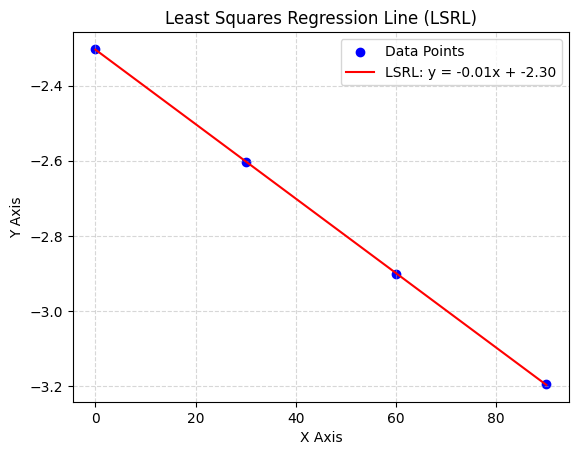

In [ ]:
# Visualize
import matplotlib.pyplot as plt
x = pointList[:, 0]
y = pointList[:, 1]
x_line = np.linspace(x.min(), x.max(), 100)
y_line = weights[1] * x_line + weights[0]
# 5. Create the visualization
plt.scatter(x, y, color='blue', label='Data Points')  # Plot raw coordinates
plt.plot(x_line, y_line, color='red', label=f'LSRL: y = {weights[1]:.2f}x + {weights[0]:.2f}')  # Plot LSRL

# 6. Customize and display
plt.xlabel('X Axis')
plt.ylabel('Y Axis')
plt.title('Least Squares Regression Line (LSRL)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

# Extension to Multidegree Polynomials
The neat thing about the above funciton is that it can be extended to multidegree polynomials.

In [ ]:
import numpy as np
def LSRL(points, deg):
  # convert it to Ax = b form
  b = points[:, 1]
  A = np.ones([len(points), 1])
  for i in range (1, deg+1):
    A = np.hstack([A, (points[:, 0]**i).reshape(len(points), 1)])
  x = np.matmul(np.linalg.inv(np.matmul(np.matrix_transpose(A), A)), np.matmul(np.matrix_transpose(A),b))
  return x

In [ ]:
pointList = np.random.random([100, 2])
weights = LSRL(pointList, 67)
print(weights)

[-2.09260766e+01  1.13885127e+03 -1.97995265e+04  2.05028617e+05
 -1.58161830e+06  9.27484588e+06 -3.91828070e+07  1.14554894e+08
 -2.23758414e+08  2.67420509e+08 -1.23424861e+08 -1.61965326e+08
  3.51550956e+08 -3.01776622e+08  1.35900923e+08 -3.37638172e+07
  2.05010235e+07 -2.36458000e+07  7.48656012e+06  5.37193362e+06
 -6.45357700e+06  4.82402450e+06 -1.64204225e+06  2.30682400e+06
  4.50358000e+06 -8.82114800e+06 -2.74311200e+06  4.76082900e+06
 -6.93703550e+06  1.35364480e+07 -5.16399000e+06 -8.51025125e+05
 -6.11393000e+05 -6.59370200e+06  4.59990750e+06  5.93196400e+06
  1.06638300e+06  4.76139288e+06 -8.21346400e+06 -4.95860200e+06
 -5.60603900e+06  5.97551500e+05  1.02621760e+07  4.96236750e+05
  5.31000400e+06 -1.19874800e+07  1.11971460e+07 -4.16247525e+06
 -5.11787250e+05 -7.11986800e+06 -6.30599550e+06  1.52091000e+07
 -1.36048560e+07  1.10305380e+07  7.61611900e+06 -6.01461125e+05
  8.37847000e+05 -1.56770360e+07 -2.78628725e+06  8.57114100e+06
  1.10262300e+07 -1.39595

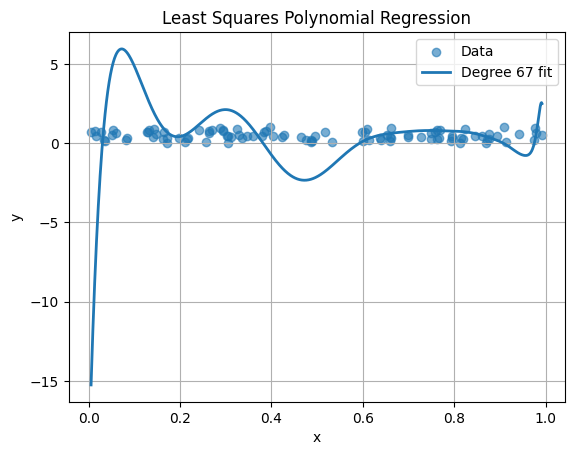

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

plt.scatter(pointList[:, 0], pointList[:, 1], alpha=0.6, label="Data")

x_fit = np.linspace(
    pointList[:, 0].min(),
    pointList[:, 0].max(),
    1000
)

# Works for any degree
y_fit = np.zeros_like(x_fit)
for i, w in enumerate(weights):
    y_fit += w * x_fit**i

plt.plot(x_fit, y_fit, linewidth=2,
         label=f"Degree {len(weights)-1} fit")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Least Squares Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()